# Практическая работа № 4. Интерполирование и экстраполирование функций

Вариант: 9

**Цель:** построить многочлен Лагранжа и кубический сплайн, вычислить промежуточные значения по Ньютону и оценить погрешности.

**Вариант 9.** Узлы для заданий 1 и 3: $(-4;2)$, $(-2;8)$, $(0;5)$, $(3;10)$. Для задания 2 используется таблица значений $f(x)=\lg(x)/x+x^2$ при $x=2{,}9$. Для заданий 4–5 — табличные значения $\sin x$.

In [1]:
import math

X4 = [-4.0, -2.0, 0.0, 3.0]

Y4 = [2.0, 8.0, 5.0, 10.0]

X8 = [1.3, 2.1, 3.7, 4.5, 6.1, 7.7, 8.5]

Y8 = [1.7777, 4.5634, 13.8436, 20.3952, 37.3387, 59.4051, 72.3593]

X_STAR = 2.9

def f8(x):
    return math.log10(x) / x + x * x

X14 = [round(1.10 + 0.05 * i, 2) for i in range(11)]

Y14 = [0.89121, 0.91276, 0.93204, 0.94898, 0.96356, 0.97572,
       0.98545, 0.99271, 0.99749, 0.99973, 0.99957]

H14 = 0.05

SUB_A, SUB_B, SUB_H = 1.25, 1.50, 0.025   # задание 4

X1, X2 = 1.03, 1.64                       # задание 5

### Вспомогательные функции для формул Ньютона

In [2]:
from math import factorial

def finite_differences(ys):
    """Таблица конечных разностей: diffs[k][i] = Δ^k y_i."""
    diffs = [list(ys)]
    while len(diffs[-1]) > 1:
        prev = diffs[-1]
        diffs.append([round(prev[i + 1] - prev[i], 10) for i in range(len(prev) - 1)])
    return diffs

def newton_forward(xs, ys, x, order):
    """Первая формула Ньютона от узла x0 = xs[0]: t = (x - x0)/h."""
    h = xs[1] - xs[0]
    t = (x - xs[0]) / h
    diffs = finite_differences(ys)
    s, term = ys[0], 1.0
    for k in range(1, order + 1):
        term *= (t - (k - 1))
        s += term * diffs[k][0] / factorial(k)
    return s, t

def newton_backward(xs, ys, x, order):
    """Вторая формула Ньютона от узла xn = xs[-1]: t = (x - xn)/h."""
    h = xs[1] - xs[0]
    t = (x - xs[-1]) / h
    diffs = finite_differences(ys)
    s, term = ys[-1], 1.0
    for k in range(1, order + 1):
        term *= (t + (k - 1))
        s += term * diffs[k][-1] / factorial(k)
    return s, t

## Задание 1. Интерполяционный многочлен Лагранжа

По четырём узлам строим многочлен степени не выше 3 и проверяем значения в узлах. График строится с помощью Matplotlib.

Слагаемые многочлена Лагранжа:
  y0 * (x + 2) x (x - 3) / -56  = 2/-56 * (x + 2) x (x - 3)
  y1 * (x + 4) x (x - 3) / 20  = 8/20 * (x + 4) x (x - 3)
  y2 * (x + 4) (x + 2) (x - 3) / -24  = 5/-24 * (x + 4) (x + 2) (x - 3)
  y3 * (x + 4) (x + 2) x / 105  = 10/105 * (x + 4) (x + 2) x

L3(x) = 211/840x^3 + 107/280x^2 - 731/420x + 5
В десятичной записи: L3(x) = +0.251190x^3 +0.382143x^2 -1.740476x^1 +5.000000x^0
Проверка в узлах:
  L3(-4) = 2.000000  (табл. 2)
  L3(-2) = 8.000000  (табл. 8)
  L3(0) = 5.000000  (табл. 5)
  L3(3) = 10.000000  (табл. 10)
numpy.polyfit (старшая степень первой): 0.251190, 0.382143, -1.740476, 5.000000
График сохранён: graph_lagrange.png


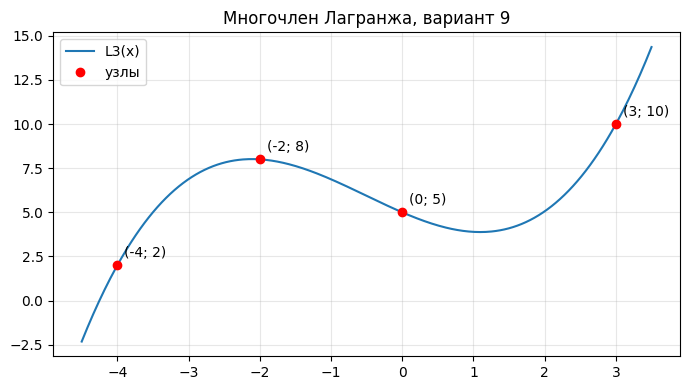

In [3]:
import os

from fractions import Fraction as Fr

import matplotlib

import matplotlib.pyplot as plt

import numpy as np

def poly_mul(p, q):
    r = [Fr(0)] * (len(p) + len(q) - 1)
    for i, a in enumerate(p):
        for j, b in enumerate(q):
            r[i + j] += a * b
    return r

def lagrange_coeffs(xs, ys):
    """Коэффициенты многочлена по возрастанию степеней: [a0, a1, a2, a3]."""
    xs = [Fr(x).limit_denominator() for x in xs]
    ys = [Fr(y).limit_denominator() for y in ys]
    n = len(xs)
    total = [Fr(0)] * n
    print("Слагаемые многочлена Лагранжа:")
    for i in range(n):
        num = [Fr(1)]
        den = Fr(1)
        for j in range(n):
            if j != i:
                num = poly_mul(num, [-xs[j], Fr(1)])
                den *= xs[i] - xs[j]
        factors = " ".join(("x" if xs[j] == 0 else f"(x {'-' if xs[j] > 0 else '+'} {abs(xs[j])})") for j in range(n) if j != i)
        print(f"  y{i} * {factors} / {den}  = {ys[i]}/{den} * {factors}")
        for k in range(n):
            total[k] += ys[i] * num[k] / den
    return total

def show(c):
    terms = []
    for k in reversed(range(len(c))):
        if c[k] == 0:
            continue
        v = float(c[k])
        part = f"{abs(c[k])}"
        if k == 1:
            part += "x"
        elif k > 1:
            part += f"x^{k}"
        terms.append(("- " if v < 0 else "+ ") + part)
    return " ".join(terms).lstrip("+ ")

c = lagrange_coeffs(X4, Y4)
print("\nL3(x) =", show(c))
print("В десятичной записи: L3(x) = " + " ".join(f"{float(c[k]):+.6f}x^{k}" for k in reversed(range(4))))
print("Проверка в узлах:")
for x, y in zip(X4, Y4):
    v = sum(float(c[k]) * x ** k for k in range(4))
    print(f"  L3({x:g}) = {v:.6f}  (табл. {y:g})")
pf = np.polyfit(X4, Y4, 3)
print("numpy.polyfit (старшая степень первой):", ", ".join(f"{v:.6f}" for v in pf))

xx = np.linspace(-4.5, 3.5, 400)
yy = np.polyval([float(c[k]) for k in reversed(range(4))], xx)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xx, yy, label="L3(x)")
ax.plot(X4, Y4, "ro", label="узлы")
for x, y in zip(X4, Y4):
    ax.annotate(f"({x:g}; {y:g})", (x, y), textcoords="offset points", xytext=(5, 6))
ax.grid(alpha=0.3); ax.legend(); ax.set_title("Многочлен Лагранжа, вариант 9")
fig.tight_layout()
path = os.path.join(os.getcwd(), "graph_lagrange.png")
fig.savefig(path, dpi=150)
print("График сохранён:", path)

## Задание 2. Значение функции при x = 2,9

Интерполяция по табличным данным с расчётом множителей многочлена Лагранжа. Результат сравнивается со значением исходной функции.

In [4]:
def lagrange_table(xs, ys, x):
    n = len(xs)
    total = 0.0
    prod = 1.0
    rows = []
    for i in range(n):
        row = [(x - xs[i]) if i == j else (xs[i] - xs[j]) for j in range(n)]
        D = 1.0
        for v in row:
            D *= v
        rows.append((row, D, ys[i] / D))
        total += ys[i] / D
        prod *= x - xs[i]
    return rows, prod, total, prod * total

def lagrange(xs, ys, x):
    s = 0.0
    for i in range(len(xs)):
        p = ys[i]
        for j in range(len(xs)):
            if j != i:
                p *= (x - xs[j]) / (xs[i] - xs[j])
        s += p
    return s

rows, prod, total, L = lagrange_table(X8, Y8, X_STAR)
print(f"x = {X_STAR}")
print("Расчётная таблица:")
for i, (row, D, q) in enumerate(rows):
    print(f"  i={i}: " + " ".join(f"{v:7.2f}" for v in row) + f" | D_i = {D:12.4f} | y_i/D_i = {q:+.6f}")
print(f"П(x) = {prod:.6f}")
print(f"Σ y_i/D_i = {total:.6f}")
print(f"L(2,9) = П·Σ = {L:.4f}")
print(f"Проверка функцией lagrange(): {lagrange(X8, Y8, X_STAR):.4f}")
exact = f8(X_STAR)
print(f"Точное значение f(2,9) = {exact:.4f}; погрешность {abs(L - exact):.4f}")

x = 2.9
Расчётная таблица:
  i=0:    1.60   -0.80   -2.40   -3.20   -4.80   -6.40   -7.20 | D_i =    2174.3272 | y_i/D_i = +0.000818
  i=1:    0.80    0.80   -1.60   -2.40   -4.00   -5.60   -6.40 | D_i =    -352.3215 | y_i/D_i = -0.012952
  i=2:    2.40    1.60   -0.80   -0.80   -2.40   -4.00   -4.80 | D_i =    -113.2462 | y_i/D_i = -0.122243
  i=3:    3.20    2.40    0.80   -1.60   -1.60   -3.20   -4.00 | D_i =     201.3266 | y_i/D_i = +0.101304
  i=4:    4.80    4.00    2.40    1.60   -3.20   -1.60   -2.40 | D_i =    -905.9697 | y_i/D_i = -0.041214
  i=5:    6.40    5.60    4.00    3.20    1.60   -4.80   -0.80 | D_i =    2818.5723 | y_i/D_i = +0.021076
  i=6:    7.20    6.40    4.80    4.00    2.40    0.80   -5.60 | D_i =   -9512.6815 | y_i/D_i = -0.007607
П(x) = -140.928614
Σ y_i/D_i = -0.060818
L(2,9) = П·Σ = 8.5711
Проверка функцией lagrange(): 8.5711
Точное значение f(2,9) = 8.5694; погрешность 0.0016


## Задание 3. Кубический сплайн

Естественный кубический сплайн имеет условия $S''(x_0)=S''(x_n)=0$. Коэффициенты находятся из трёхдиагональной системы. Проверяем значения в узлах и сравниваем с SciPy.

Система (4.31) для c_1..c_{n-1}:
  i=2: 2·c0 + 8·c1 + 2·c2 = -27/2 (-13.5000)
  i=3: 2·c1 + 10·c2 + 3·c3 = 19/2 (9.5000)
c: c0 = 0 ≈ 0.00000, c1 = -77/38 ≈ -2.02632, c2 = 103/76 ≈ 1.35526, c3 = 0 ≈ 0.00000

Коэффициенты сплайна:
 i |      отрезок |      a_i |       b_i |       c_i |       d_i
 1 | [-4; -2]      |   8.0000 |   0.29825 |  -2.02632 |  -0.33772
 2 | [-2; 0]       |   5.0000 |  -1.04386 |   1.35526 |   0.56360
 3 | [0; 3]        |  10.0000 |   3.02193 |   0.00000 |  -0.15058

Формулы:
  P1(x) = 8 +0.29825(x + 2) -2.02632(x + 2)^2 -0.33772(x + 2)^3,  x ∈ [-4; -2]
  P2(x) = 5 -1.04386x +1.35526x^2 +0.56360x^3,  x ∈ [-2; 0]
  P3(x) = 10 +3.02193(x - 3) +0.00000(x - 3)^2 -0.15058(x - 3)^3,  x ∈ [0; 3]

Проверка в узлах:
  S(-4) = 2.000000  (табл. 2)
  S(-2) = 8.000000  (табл. 8)
  S(0) = 5.000000  (табл. 5)
  S(3) = 10.000000  (табл. 10)
Сравнение с scipy CubicSpline(natural): макс. расхождение 3.6e-15
График сохранён: graph_spline.png


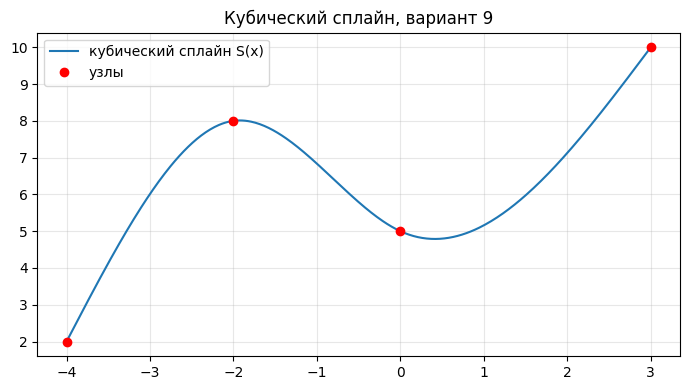

In [5]:
import os

from fractions import Fraction as Fr

import matplotlib

import matplotlib.pyplot as plt

import numpy as np

from scipy.interpolate import CubicSpline

def solve_tridiag(a, b, c, d):
    """Метод прогонки: a — поддиагональ, b — диагональ, c — наддиагональ."""
    n = len(b)
    cp, dp = [Fr(0)] * n, [Fr(0)] * n
    cp[0] = c[0] / b[0] if n > 1 else Fr(0)
    dp[0] = d[0] / b[0]
    for i in range(1, n):
        m = b[i] - a[i] * cp[i - 1]
        cp[i] = c[i] / m if i < n - 1 else Fr(0)
        dp[i] = (d[i] - a[i] * dp[i - 1]) / m
    x = [Fr(0)] * n
    x[-1] = dp[-1]
    for i in range(n - 2, -1, -1):
        x[i] = dp[i] - cp[i] * x[i + 1]
    return x

def spline(xs, ys):
    xs = [Fr(x).limit_denominator() for x in xs]
    ys = [Fr(y).limit_denominator() for y in ys]
    n = len(xs) - 1
    h = [None] + [xs[i] - xs[i - 1] for i in range(1, n + 1)]
    # неизвестные c_1..c_{n-1}; c_0 = c_n = 0
    m = n - 1
    sub, diag, sup, rhs = [], [], [], []
    print("Система (4.31) для c_1..c_{n-1}:")
    for i in range(2, n + 1):
        sub.append(h[i - 1])
        diag.append(2 * (h[i - 1] + h[i]))
        sup.append(h[i])
        r = 3 * ((ys[i] - ys[i - 1]) / h[i] - (ys[i - 1] - ys[i - 2]) / h[i - 1])
        rhs.append(r)
        print(f"  i={i}: {h[i - 1]}·c{i - 2} + {2 * (h[i - 1] + h[i])}·c{i - 1} + {h[i]}·c{i} = {r} ({float(r):.4f})")
    cin = solve_tridiag(sub, diag, sup, rhs) if m > 0 else []
    c = [Fr(0)] + cin + [Fr(0)]
    a = [None] + [ys[i] for i in range(1, n + 1)]
    d = [None] + [(c[i] - c[i - 1]) / (3 * h[i]) for i in range(1, n + 1)]
    b = [None] + [(ys[i] - ys[i - 1]) / h[i] + h[i] * c[i] - h[i] ** 2 * d[i] for i in range(1, n + 1)]
    return xs, h, a, b, c, d

def S(x, xs, a, b, c, d):
    n = len(xs) - 1
    for i in range(1, n + 1):
        if x <= float(xs[i]) or i == n:
            t = x - float(xs[i])
            return float(a[i]) + float(b[i]) * t + float(c[i]) * t ** 2 + float(d[i]) * t ** 3

xs, h, a, b, c, d = spline(X4, Y4)
n = len(xs) - 1
print("c:", ", ".join(f"c{i} = {c[i]} ≈ {float(c[i]):.5f}" for i in range(n + 1)))
print("\nКоэффициенты сплайна:")
print(f"{'i':>2} | {'отрезок':>12} | {'a_i':>8} | {'b_i':>9} | {'c_i':>9} | {'d_i':>9}")
for i in range(1, n + 1):
    print(f"{i:2d} | [{float(xs[i - 1]):g}; {float(xs[i]):g}]".ljust(18) +
          f" | {float(a[i]):8.4f} | {float(b[i]):9.5f} | {float(c[i]):9.5f} | {float(d[i]):9.5f}")
print("\nФормулы:")
for i in range(1, n + 1):
    xi = float(xs[i])
    shift = f"(x {'-' if xi > 0 else '+'} {abs(xi):g})" if xi != 0 else "x"
    print(f"  P{i}(x) = {float(a[i]):g} {float(b[i]):+.5f}{shift} {float(c[i]):+.5f}{shift}^2 {float(d[i]):+.5f}{shift}^3,"
          f"  x ∈ [{float(xs[i - 1]):g}; {xi:g}]")
print("\nПроверка в узлах:")
for x, y in zip(X4, Y4):
    print(f"  S({x:g}) = {S(x, xs, a, b, c, d):.6f}  (табл. {y:g})")
cs = CubicSpline(X4, Y4, bc_type="natural")
grid = np.linspace(X4[0], X4[-1], 41)
dev = max(abs(S(x, xs, a, b, c, d) - cs(x)) for x in grid)
print(f"Сравнение с scipy CubicSpline(natural): макс. расхождение {dev:.1e}")

xx = np.linspace(X4[0], X4[-1], 400)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xx, [S(x, xs, a, b, c, d) for x in xx], label="кубический сплайн S(x)")
ax.plot(X4, Y4, "ro", label="узлы")
ax.grid(alpha=0.3); ax.legend(); ax.set_title("Кубический сплайн, вариант 9")
fig.tight_layout()
path = os.path.join(os.getcwd(), "graph_spline.png")
fig.savefig(path, dpi=150)
print("График сохранён:", path)

## Задание 4. Уплотнение таблицы по Ньютону

Уплотнение табличных значений на $[1{,}25;1{,}50]$ с шагом $0{,}025$. Используются конечные разности и интерполяционный многочлен Ньютона степени 3.

In [6]:
import math

ORDER = 3

def print_diffs():
    diffs = finite_differences(Y14)
    print("Таблица конечных разностей (табл. 4.14):")
    print(f"{'x':>5} | {'y':>8} | {'Δy':>8} | {'Δ²y':>8} | {'Δ³y':>8} | {'Δ⁴y':>8}")
    for i, x in enumerate(X14):
        cells = [f"{diffs[k][i]:8.5f}" if i < len(diffs[k]) else " " * 8 for k in range(5)]
        print(f"{x:5.2f} | " + " | ".join(cells))
    return diffs

def value(x):
    # ближайший слева узел
    i0 = min(int(round((x - X14[0]) / H14, 9)), len(X14) - 1)
    if i0 + ORDER <= len(X14) - 1:
        xs, ys = X14[i0:i0 + ORDER + 1], Y14[i0:i0 + ORDER + 1]
        v, t = newton_forward(xs, ys, x, ORDER)
        return v, f"1-я, x0={xs[0]:.2f}, t={t:+.2f}"
    xs, ys = X14[-ORDER - 1:], Y14[-ORDER - 1:]
    v, t = newton_backward(xs, ys, x, ORDER)
    return v, f"2-я, xn={xs[-1]:.2f}, t={t:+.2f}"

print_diffs()
print("\nВторые разности почти постоянны (≈ -0,0024), третьи — порядка 1e-5, на уровне ошибки округления;")
print(f"берём многочлен Ньютона степени {ORDER}.")
print("Скачок Δ³ = +0,00014 и Δ⁴ = +0,00020 в конце таблицы указывает на ошибку в y(1,55):")
print("в учебнике 0,99973, а sin 1,55 = 0,99978. Расчёт ведётся по данным учебника.\n")
n = round((SUB_B - SUB_A) / SUB_H)
print(f"{'x':>6} | {'y (Ньютон)':>10} | {'sin x':>8} | {'|разн.|':>8} | формула")
for k in range(n + 1):
    x = round(SUB_A + k * SUB_H, 4)
    v, how = value(x)
    print(f"{x:6.3f} | {v:10.5f} | {math.sin(x):8.5f} | {abs(v - math.sin(x)):8.1e} | {how}")

Таблица конечных разностей (табл. 4.14):
    x |        y |       Δy |      Δ²y |      Δ³y |      Δ⁴y
 1.10 |  0.89121 |  0.02155 | -0.00227 | -0.00007 |  0.00005
 1.15 |  0.91276 |  0.01928 | -0.00234 | -0.00002 | -0.00004
 1.20 |  0.93204 |  0.01694 | -0.00236 | -0.00006 |  0.00005
 1.25 |  0.94898 |  0.01458 | -0.00242 | -0.00001 | -0.00003
 1.30 |  0.96356 |  0.01216 | -0.00243 | -0.00004 |  0.00003
 1.35 |  0.97572 |  0.00973 | -0.00247 | -0.00001 | -0.00005
 1.40 |  0.98545 |  0.00726 | -0.00248 | -0.00006 |  0.00020
 1.45 |  0.99271 |  0.00478 | -0.00254 |  0.00014 |         
 1.50 |  0.99749 |  0.00224 | -0.00240 |          |         
 1.55 |  0.99973 | -0.00016 |          |          |         
 1.60 |  0.99957 |          |          |          |         

Вторые разности почти постоянны (≈ -0,0024), третьи — порядка 1e-5, на уровне ошибки округления;
берём многочлен Ньютона степени 3.
Скачок Δ³ = +0,00014 и Δ⁴ = +0,00020 в конце таблицы указывает на ошибку в y(1,55):
в учебнике

## Задание 5. Экстраполяция

Вычисляем значения при $x_1=1{,}03$ и $x_2=1{,}64$, лежащих за пределами исходной сетки. Сравниваем с $\sin x$.

In [7]:
import math

ORDER = 3

v1, t1 = newton_forward(X14, Y14, X1, ORDER)
v2, t2 = newton_backward(X14, Y14, X2, ORDER)
print(f"y({X1}) по 1-й формуле: t = ({X1} - 1,10)/0,05 = {t1:+.2f}; y = {v1:.5f}; sin = {math.sin(X1):.5f}; разн. {abs(v1 - math.sin(X1)):.1e}")
print(f"y({X2}) по 2-й формуле: t = ({X2} - 1,60)/0,05 = {t2:+.2f}; y = {v2:.5f}; sin = {math.sin(X2):.5f}; разн. {abs(v2 - math.sin(X2)):.1e}")
# В табл. 4.14 значение при x = 1,55 напечатано с ошибкой: 0,99973 вместо sin 1,55 = 0,99978
# (видно по скачку разностей 3-го и 4-го порядка в конце таблицы). Пересчёт с исправленным значением:
Yfix = list(Y14)
Yfix[X14.index(1.55)] = 0.99978
v2f, _ = newton_backward(X14, Yfix, X2, ORDER)
print(f"y({X2}) с исправленным y(1,55) = 0,99978: y = {v2f:.5f}; разн. с sin {abs(v2f - math.sin(X2)):.1e}")

y(1.03) по 1-й формуле: t = (1.03 - 1,10)/0,05 = -1.40; y = 0.85736; sin = 0.85730; разн. 6.1e-05
y(1.64) по 2-й формуле: t = (1.64 - 1,60)/0,05 = +0.80; y = 0.99781; sin = 0.99761; разн. 2.0e-04
y(1.64) с исправленным y(1,55) = 0,99978: y = 0.99760; разн. с sin 1.1e-05


**Вывод.** Многочлен Лагранжа и сплайн проходят через все четыре заданные точки; при большом числе узлов сплайн часто устойчивее глобального многочлена. По таблице Ньютона можно получить дополнительные значения внутри сетки и оценить экстраполяцию за её пределами. В исходной таблице при $x=1{,}55$ сохранено значение $0{,}99973$, отличающееся от $\sin(1{,}55)\approx0{,}99978$; сравнение с исправлением вынесено в задание 5.